In [1]:
import sys
sys.path.append("..")
 
import numpy as np
import matplotlib.pyplot as plt
import torch
from src.utils import compress_learned, get_distilbert_tokenizer  # <-- both missing
from src.scorer import load_scorer                                 # <-- missing
 
scorer = load_scorer("../models/scorer.pt")
tok    = get_distilbert_tokenizer()  

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [2]:
import matplotlib.colors as mcolors


In [3]:
def plot_salience(text: str, ratio: float = 0.5):
    result = compress_learned(text, scorer, ratio)
    tokens, scores = result["tokens"], result["scores"]
    scores_arr = np.array(scores)
    threshold = np.sort(scores_arr)[::-1][int(len(scores_arr) * ratio)]

    fig, ax = plt.subplots(figsize=(14, 1.8))
    cmap = plt.get_cmap("RdYlGn")
    for i, (tok_str, sc) in enumerate(zip(tokens, scores_arr)):
        color = cmap(sc)
        ax.add_patch(plt.Rectangle((i, 0), 0.9, 1, color=color, alpha=0.85))
        ax.text(i + 0.45, 0.5, tok_str.replace("▁", "").replace("Ġ", " "),
                ha="center", va="center", fontsize=8,
                color="black" if sc > 0.3 else "white")
        if sc < threshold:
            ax.add_patch(plt.Rectangle((i, 0), 0.9, 1,
                         fill=False, edgecolor="red", linewidth=1.5))
    ax.set_xlim(0, len(tokens)); ax.set_ylim(0, 1)
    ax.axis("off"); plt.tight_layout(); plt.show()

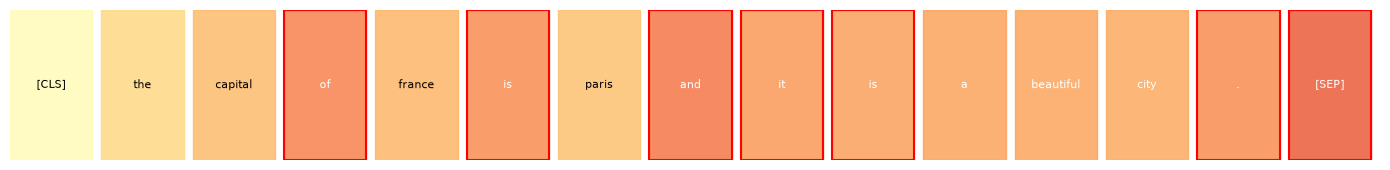

In [4]:
plot_salience("The capital of France is Paris and it is a beautiful city.", ratio=0.5)


In [5]:
negation_test = [
    "The treaty was NOT signed in 1814.",
    "Paris is NOT the capital of Germany.",
]
for text in negation_test:
    r = compress_learned(text, scorer, ratio=0.5)
    print(f"Original:   {text}")
    print(f"Compressed: {r['compressed']}\n")

Original:   The treaty was NOT signed in 1814.
Compressed: [CLS] the treaty signed in

Original:   Paris is NOT the capital of Germany.
Compressed: [CLS] paris not capital germany

